# Provide code test its behaviour and identify the issue
how does the provided vision work?

### Checklist
- subscribe raw_camera/compressed why use it?
- we ve already transform the image to cv form
- 没有上下边界的截断
- 没有任何截断，如果墙体遮挡也应该截断
- 一张图片会添加两个marker吗？我的设想是不会，因为alignment
- alignment 具体逻辑是什么？

> import all the required package

In [218]:
import cv2
import math
import matplotlib.pyplot as plt


### Color setting

In [219]:

colours = {
	"pink":	 	((150,50,0), (172, 255, 255)), # color bound (calibrate?)
	"blue":		((93, 100,0), (105, 255, 255)), # ((100,0,0), (130, 255, 255)),
	"green":	((65,100,0), (90, 255, 255)), # ((40,0,0), (80, 255, 255)),
	"yellow":	((21,150,0), (32, 255, 255))
}


field_of_view_h = 62.2
field_of_view_v = 48.8
focal_length = 3.04
pixel_size = 0.0475
real_object_size = 100.0
distance_numerator = 33 #real_object_size * focal_length * pixel_size

In [220]:


def segment(current_frame, hsv_frame, colour):
	"""
	Mask out everything except the specified colour
	Connect pixels to form a blob
	"""
	# set the lower and upper bound of the image
	(lower, upper) = colours[colour]

	# Mask out everything except pixels of colour parameter
	mask = cv2.inRange(hsv_frame, lower, upper)
	result = cv2.bitwise_and(current_frame, current_frame, mask=mask)

	# Run 4-way connected components, with statistics
	blobs = cv2.connectedComponentsWithStats(mask, 4, cv2.CV_32S)

	# Display masked image

	# 假设你的 result 是通过 cv2.bitwise_and 得到的 BGR 格式图像
	# OpenCV 默认是 BGR，而 matplotlib 显示的是 RGB，需要先转换一下色彩通道
	result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

	# 使用 matplotlib 绘制并显示
	plt.figure(figsize=(6, 6))
	plt.imshow(result_rgb)

	plt.show()
	#cv2.imshow("result", result)

	# Print statistics for each blob (connected component)
	return get_stats(blobs, colour)


def get_stats(blobs, colour):
	"""
	Print statistics for each blob (connected component)
	of the specified colour
	Return the centroid and height of the largest blob, if there is one.
	"""

	(numLabels, labels, stats, centroids) = blobs
	if numLabels == 0:
		return None

	largest = 0
	rval = None
	centre = 80 # 640/2

	for i in range(1, numLabels):
		x = stats[i, cv2.CC_STAT_LEFT]
		y = stats[i, cv2.CC_STAT_TOP]
		w = stats[i, cv2.CC_STAT_WIDTH]
		h = stats[i, cv2.CC_STAT_HEIGHT]
		area = stats[i, cv2.CC_STAT_AREA]
		(cx, cy) = centroids[i]
#		print(colour, x, y, w, h, area, cx, cy)

		if area > largest:
			largest = area
			# distance = 35.772 * pow(h, -0.859) # obtained experimentally
			distance = distance_numerator / h # https://www.baeldung.com/cs/cv-compute-distance-from-object-video
			"""
			The condition below accounts for when the marker is at the edge of the screen
			and is only paritally visible. The assumption is that if the aspect ratio < 0.8
			then it is only partially visisble.
			We need two cases for when the marker is on the left or right edge.
			"""
			aspect_ratio = h/w
			print(f'distance: {distance}')
			print(f'ratios: {aspect_ratio}')
			# if aspect_ratio < 0.8:

			# 	if cx < centre:
			# 		cx += h-w
			# 	else:
			# 		cx -= h-w
			angle = (centre - cx) * field_of_view_h / 180
			if angle < 0:
				angle += 360
			print(f'angle:{angle}')
			rval = (cx, cy, h, distance, angle)
	print(colour, rval)

	return rval

### main function run the images.

(120, 160, 3)
hsv val: [173  87 167]


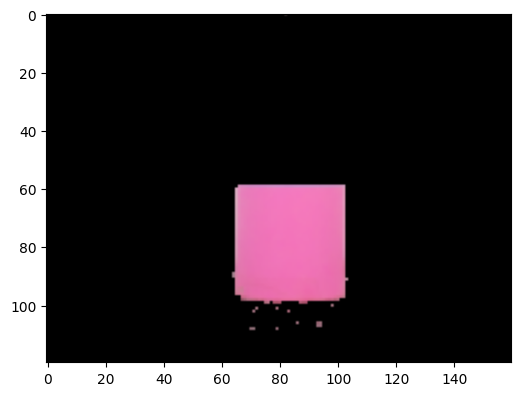

distance: 33.0
ratios: 1.0
angle:359.3088888888889
distance: 0.8048780487804879
ratios: 1.025
angle:358.78624744823566
pink (83.51246719160105, 78.56758530183727, 41, 0.8048780487804879, 358.78624744823566)


In [221]:
file = "valid_img/blu2.png"
current_frame = cv2.imread(file)
print(current_frame.shape)

hsv_frame = cv2.cvtColor(current_frame, cv2.COLOR_BGR2HSV)
print(f'hsv val: {hsv_frame[101, 80]}')
pink_blob = segment(current_frame, hsv_frame, "pink")

### do what

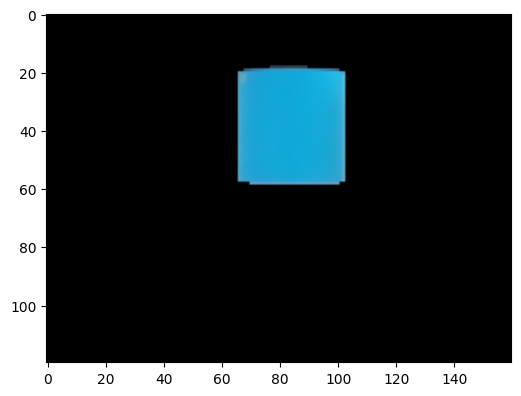

distance: 0.8048780487804879
ratios: 1.1081081081081081
angle:358.6135835768337
blue (84.01213755900203, 38.29399865138233, 41, 0.8048780487804879, 358.6135835768337)


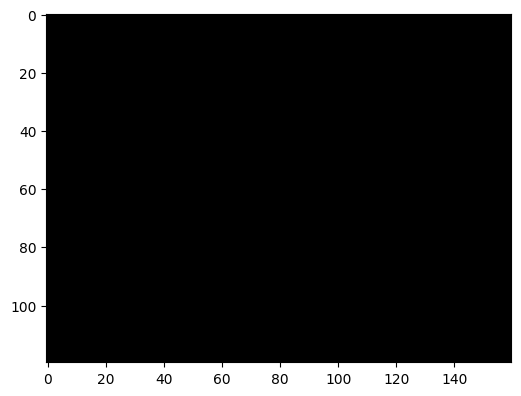

green None


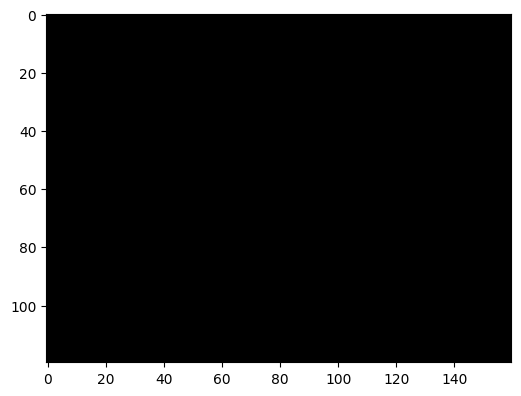

yellow None


In [222]:
if pink_blob:
			(pink_x, pink_y, pink_h, p_d, p_a) = pink_blob

			for c in ["blue", "green", "yellow"]:
				blob = segment(current_frame, hsv_frame, c)